# Диагностика колоректального рака по микробиоте кишечника

**Кейс Генотек · GutSignal · ансамбль SVM + CatBoost + логистическая регрессия · метрика ROC AUC**

Блокнот строит модель, которая по относительным численностям 849 бактериальных таксонов (mOTU) и метаданным образца оценивает вероятность колоректального рака (КРР). Это бинарная классификация: `label = 1` означает case (КРР), `label = 0` означает control.

**Результат.** Ансамбль SVM, CatBoost и логистической регрессии оценивается по OOF ROC AUC на кросс-валидации 5 × 2 (подробности в разделе «Результаты»). Точное значение печатается при запуске раздела 5.

**Как запустить.** Загрузите `train.csv` и `test.csv` в рабочую папку (в Colab папка `/content`) и выполните все ячейки сверху вниз. Время работы зависит от процессора и составляет от нескольких минут до десятков минут; быстрый режим без валидации включается флагом `RUN_VALIDATION = False`.

### Карта блокнота

| Раздел | Что делает | Зачем нужен |
|---|---|---|
| Описание решения | Литература, признаки, отбор, ковариаты, разбиение, результаты | Краткая запись подхода для защиты |
| 1. Подготовка | Библиотеки, настройки, загрузка данных | Воспроизводимый старт |
| 2. Данные и ковариаты | Состав когорт, дисбалансы метаданных | Понять, что модель может выучить вместо микробного сигнала |
| 3. Признаки | Функции обработки внутри фолда | Все обучаемые параметры считаются только по обучающей части |
| 4. Модели | SVM, CatBoost, ансамбль | Сам алгоритм предсказания |
| 5. Валидация | Три схемы кросс-валидации, ROC-кривая | Честная оценка качества |
| 6. Ключевые таксоны | Таблица самых информативных таксонов | Биологическая интерпретация |
| 7. Финальное обучение | Обучение на всём train и `submission.csv` | Итоговый файл с прогнозами |
| Справочник | Термины и формулы | Быстро вспомнить, что означает каждое понятие |

## Описание решения

Ниже шесть пунктов, по которым описывается подход. Каждое утверждение соответствует коду блокнота.

### Литература

**Актуальность.** Колоректальный рак входит в число самых частых и опасных онкологических заболеваний, а диагностика часто запаздывает. Метагеномика образца стула даёт неинвазивный способ скрининга, поэтому связь состава кишечной микробиоты с КРР активно изучается.

**На что опирались.**

- *Piccinno G. et al., Nature Medicine, 2025, 31(7), 2416–2429* (doi: 10.1038/s41591-025-03693-9). Объединённый анализ 3 741 метагеномов стула из 18 когорт. Работа показывает, что микробный сигнал КРР воспроизводится между когортами, а средняя точность по ROC AUC на метагеномных данных составляет около 0.85. Среди значимых находок есть оральные микроорганизмы и отдельные клады *Fusobacterium nucleatum*. Отсюда в нашем решении две идеи: оценивать таксоны **внутри каждой когорты** и усреднять эффект, а качество проверять схемой **LOCO** (когорта целиком исключается из обучения).
- *Avuthu N., Guda C., Microbiology Spectrum, 2022, 10(4), e00013-22* (doi: 10.1128/spectrum.00013-22). Метаанализ метагеномных данных из США, Китая и Франции с классификаторами на основе деревьев (Random Forest). Отсюда выбор древесной модели (CatBoost) и решение учитывать когорту как явный фактор.
- *Kaggle-работа aramelheni «AI-Powered Gut Microbiome Analysis for Colorectal Cancer Detection»*. Описывает связку автоматизированной предобработки данных и машинного обучения для диагностики КРР по микробиоте. Отсюда общий принцип нашего конвейера: строго воспроизводимая предобработка, вынесенная в отдельные функции.

Идея **кластеризации таксонов по венгерскому алгоритму** (сбалансированные кластеры признаков) принадлежит команде. Ее подробное объяснение дано в отдельной пояснительной записке.

### Признаки и предобработка

| Шаг | Что делается | Где считается |
|---|---|---|
| Исходные признаки | 849 mOTU (относительные численности) | train + test, без параметров обучения |
| Агрегаты | суммы численностей по роду и по виду (группы из двух и более mOTU) | без параметров обучения |
| Фильтр | оставляем mOTU и агрегаты, обнаруженные не менее чем у 4% образцов обучающей части | по обучающей части фолда |
| Ранговое преобразование | эмпирическая функция распределения (с усреднением при совпадении значений) | по обучающей части фолда |
| CLR-преобразование | логарифм доли с добавкой, равной половине минимальной ненулевой доли, затем центрирование по образцу | добавка по обучающей части фолда |
| Кластеры «гильдий» | 40 сбалансированных кластеров по корреляции рангов CLR; признаки: среднее и стандартное отклонение CLR внутри кластера (до 80 признаков) | по обучающей части фолда |
| Разнообразие | число таксонов, энтропия Шеннона, индекс Симпсона, доля самого частого таксона, доля нераспознанного, число таксонов выше порогов 1e-5, 1e-4, 1e-3 | без параметров обучения |
| Метаданные | возраст, ИМТ и флаг пропуска ИМТ, пол, логарифм глубины секвенирования, когорта | медиана для пропусков по обучающей части фолда |

`sample_id` и любые другие идентификаторы в признаки не входят.

### Отбор признаков

Отбор есть, и он выполняется внутри каждого фолда по меткам только обучающей части.

1. **Фильтр по распространённости.** Отбрасываются таксоны, редкие в обучающей части (менее 4% образцов).
2. **Ранжирование по эффекту.** Для каждого признака считается эффект «AUC − 0.5» отдельно в каждой когорте и усредняется с весами, пропорциональными корню из произведения числа case и control в когорте. Если в когорте нет одного из классов, она пропускается.
3. **Отбор для CatBoost.** В первую модель берутся 35 признаков с наибольшим по модулю эффектом, во вторую 60. Дополнительно строятся сводные признаки по группам из 5, 12, 25, 50 и 100 самых «положительных» и самых «отрицательных» таксонов (средний ранг, число обнаруженных, логарифм суммы).
4. **Веса в SVM.** Эффекты таксонов задают веса признаков в ядрах (формула вида `(0.025 + |эффект|)^степень`).
5. **Встроенная регуляризация CatBoost.** Подвыборка признаков на каждом разбиении (`rsm = 0.65`) и L2-штраф (`l2_leaf_reg = 7`).
6. **Логистическая регрессия.** Использует все отфильтрованные таксоны, а не отобранные, и держится на сильной L2-регуляризации (`C = 0.01`); ранги берутся внутри когорты.

Дополнительные биологические признаки (отношение подвидов *Fusobacterium*, суммарная доля оральных таксонов и другие) проверялись при разработке. Их вклад оказался в пределах шума (не более примерно 0.006 по AUC), поэтому в финальную модель они не включены.

### Ковариаты

Ковариаты: **когорта, возраст, ИМТ, пол, глубина секвенирования** (`library_size`). Между case и control есть дисбаланс по возрасту и глубине секвенирования (цифры в разделе 2), поэтому модель может выучить их вместо микробного сигнала.

Мы **не вычитаем** ковариаты регрессией, **не используем остатки и веса образцов**. Вместо этого сочетаем три приёма:

- **Выравнивание по когортам.** Эффект каждого таксона считается внутри когорты и только потом усредняется, поэтому разница между странами не попадает в оценку эффекта. Логистическая регрессия работает на рангах внутри когорты, поэтому тоже не опирается на различия между странами.
- **Явное включение в модель.** Когорта входит как one-hot признак и как множитель «та же когорта» в ядре SVM. Глубина секвенирования берётся в логарифме и взаимодействует с когортой (протоколы секвенирования разные). Одна из двух моделей CatBoost обучается **без возраста и ИМТ**, чтобы смесь не опиралась только на них.
- **Проверка схемой LOCO.** Когорта целиком исключается из обучения, поэтому видно, насколько модель держится на микробном сигнале, а не на когорте.

Почему так: выборка мала (415 образцов, пять когорт), регрессия и остатки добавили бы шума, а удаление когорты из признаков не сработало (проверено командой).

### Разбиение данных

Отдельного hold-out из `train.csv` не выделялось: качество считается по **OOF-прогнозам** (out-of-fold), где каждый образец оценивается моделью, не видевшей его. **Исключённых образцов нет (0 из 415).**

| Схема | Метод | Train | Validation | Case / control (train) | Case / control (validation) |
|---|---|---|---|---|---|
| Основная | `RepeatedStratifiedKFold`, 5 фолдов × 2 повтора, `random_state=7`, стратификация по классу | 332 (80.0%) | 83 (20.0%) | 164 / 168 | 41 / 42 |
| С учётом когорт | `StratifiedKFold`, 5 фолдов, seed 31 и 73, стратификация по паре «когорта × класс» | 332 (80.0%) | 83 (20.0%) | 164 / 168 | 41 / 42 |
| LOCO | `LeaveOneGroupOut`: validation равна целой когорте | 316–345 | 70–99 | 147–174 / 162–176 | 31–58 / 34–48 |

Размеры LOCO по когортам: AUS 79 (31 / 48), CHI 99 (58 / 41), FRA 80 (37 / 43), GER 87 (43 / 44), USA 70 (36 / 34). В train 415 образцов: 205 case и 210 control. Файл `test.csv` (160 образцов без меток) в валидации не участвует. Финальная модель обучается на всех 415 образцах.

### Результаты

На основной схеме (кросс-валидация 5 × 2, 415 образцов) OOF ROC AUC ансамбля печатается в разделе 5. Остальные метрики (среднее по фолдам, схема с учётом когорт, LOCO по каждой когорте) печатаются в разделе 5. При другой версии CatBoost или NumPy последние знаки могут слегка отличаться.

Качество подбиралось на тех же 415 образцах, поэтому оценка оптимистична, а на закрытой валидации оно может быть ниже. Самая строгая проверка устойчивости это LOCO.

## 1. Подготовка

**Зачем этот блок.** Он подключает библиотеки и задаёт настройки запуска. Библиотека `catboost` ставится автоматически, если её нет. Настройки:

- `RUN_VALIDATION = True` запускает валидацию (раздел 5). Значение `False` пропускает её и сразу обучает финальную модель;
- `DATA_DIR` задаёт папку с `train.csv` и `test.csv`; если файлов там нет, блокнот ищет их в `/content` (Colab).

Новые флаги `FEATURE_FLAGS`, `USE_EXTRA_GBMS`, `USE_BLEND_OPT`, `RUN_ABLATION` управляют гипотезами из EDA (описание в разделах 3–5). С настройками по умолчанию блоки исходного ноутбука работают как раньше, а к бустингу добавляются признаки группы риска и взаимодействия.

In [1]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 34.8 MB/s  0:00:02


In [2]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from scipy.special import expit
from scipy.stats import chi2_contingency, mannwhitneyu, rankdata
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import LeaveOneGroupOut, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
from IPython.display import display

%matplotlib inline

# Настройки запуска
RUN_VALIDATION = True
DATA_DIR = Path(".")
OUTPUT_PATH = Path.cwd() / "submission.csv"

# ---------------------------------------------------------------------------
# Флаги гипотез из EDA. Каждая группа признаков включается и отключается отдельно.
# Если в таблице абляции (раздел 5, «Проверка гипотез») группа ухудшает скор, поставьте её в False.
# ---------------------------------------------------------------------------
FEATURE_FLAGS = {
    "risk": True,              # флаг «женщины 65–74», возрастные корзины, возраст × пол
    "interactions": True,      # пол / риск-группа / возраст × топ-5 бактерий (CLR)
    "anthro": False,           # ИМТ: отклонение от медианы пола и возрастной корзины, ИМТ/возраст
    "country": False,          # топ-таксоны минус среднее / деление на медиану по стране
    "null_importance": False,  # отбор таксонов по Null Importance (внутри фолда)
}
USE_EXTRA_GBMS = False         # доп. бустинги LightGBM + XGBoost в ансамбле (нужны пакеты lightgbm и xgboost)
USE_BLEND_OPT = False          # подобрать веса бленда через scipy.optimize на OOF (раздел 5)
RUN_ABLATION = True            # таблица «гипотеза → OOF AUC» (раздел 5); занимает несколько минут


**Загрузка данных.** Ячейка находит `train.csv` и `test.csv`, проверяет их целостность и объявляет функции, которые не требуют обучения на данных:

- `abundance_groups` объединяет mOTU одного рода и вида в агрегаты;
- `sample_features` считает показатели разнообразия и метаданные образца.

Проверки гарантируют, что в `test.csv` нет лишних колонок, метки содержат только 0 и 1, а `sample_id` уникальны.

In [3]:
META_COLUMNS = ["sample_id", "label", "cohort", "age", "gender", "bmi", "library_size"]


def find_file(name):
    """Ищет файл в DATA_DIR, затем в /content (Colab)."""
    for folder in (DATA_DIR, Path("/content")):
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"Не найден файл {name}. Загрузите его в рабочую папку или укажите DATA_DIR.")


train = pd.read_csv(find_file("train.csv"))
test = pd.read_csv(find_file("test.csv"))
assert set(train) - set(test) == {"label"} and set(test) <= set(train)
assert set(train.label) == {0, 1}
assert pd.concat([train.sample_id, test.sample_id]).is_unique



def abundance_groups(names):
    taxonomy = [name.split(" [", 1)[0] for name in names]
    genus = [" ".join(name.removeprefix("Candidatus ").split()[:2])
             if name.startswith(("unknown ", "uncultured "))
             else name.removeprefix("Candidatus ").split()[0] for name in taxonomy]
    species = [" ".join(name.split()[:2]) if " s. " in name else name for name in taxonomy]
    groups = {}
    for level, keys in (("genus", genus), ("species", species)):
        for key in sorted(set(keys)):
            indices = np.where(np.array(keys) == key)[0]
            if len(indices) > 1:
                groups[(level, key)] = indices
    return taxonomy, genus, groups


def sample_features(data, raw):
    total = raw.sum(axis=1)
    composition = raw / total[:, None]
    diversity = np.column_stack([
        np.log1p((raw > 0).sum(axis=1)),
        -(composition * np.log(np.maximum(composition, 1e-16))).sum(axis=1),
        np.square(composition).sum(axis=1),
        composition.max(axis=1),
        1 - total,
        *(np.log1p((raw > cutoff).sum(axis=1)) for cutoff in [1e-5, 1e-4, 1e-3]),
    ])
    meta = np.column_stack([
        data.age, data.bmi, data.bmi.isna(),
        data.gender.eq("M"), data.gender.eq("F"),
        np.log10(data.library_size),
    ])
    return diversity, meta

## 2. Данные и ковариаты

**Зачем этот блок.** Прежде чем строить модель, нужно понять, чем case отличаются от control **не по бактериям**. Если возраст, глубина секвенирования или когорта связаны с меткой, модель может выучить их вместо микробного сигнала, и на закрытой валидации качество упадёт.

Здесь создаётся объект `Dataset`: он объединяет train и test, чтобы признаки считались в одном порядке строк, и содержит функцию `splits` с тремя схемами разбиения (они описаны в разделе 5). Затем печатается состав когорт.

In [4]:
class Dataset:
    def __init__(self, train, test):
        self.data = pd.concat([train, test], ignore_index=True)
        self.y = train.label.to_numpy(dtype=int)
        self.cohort = self.data.cohort.to_numpy()
        self.taxa = [name for name in train if name not in META_COLUMNS]
        self.raw = self.data[self.taxa].to_numpy(dtype=float)
        assert np.isfinite(self.raw).all() and (self.raw >= 0).all()
        assert (self.raw.sum(axis=1) > 0).all()
        self.diversity, self.meta = sample_features(self.data, self.raw)
        _, self.genus, self.groups = abundance_groups(self.taxa)
        self.aggregated = np.column_stack([self.raw[:, indices].sum(axis=1)
                                           for indices in self.groups.values()])

    def splits(self, mode):
        index = np.arange(len(self.y))
        y_cohort = np.char.add(self.cohort[index].astype(str), self.y.astype(str))
        if mode == "loco":
            return list(LeaveOneGroupOut().split(index, self.y, self.cohort[index]))
        if mode == "class":
            cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=7)
            return list(cv.split(index, self.y))
        return [(a, b) for seed in mode
                for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(index, y_cohort)]

dataset = Dataset(train, test)
print(f"Train: {len(train)} строк | Test: {len(test)} строк | Таксонов: {len(dataset.taxa)}")
display(pd.crosstab(train.cohort, train.label).rename(columns={0: "Класс 0", 1: "Класс 1"})
        .assign(test=test.cohort.value_counts()))

Train: 415 строк | Test: 160 строк | Таксонов: 849


label,Класс 0,Класс 1,test
cohort,,,
AUS,48,31,30
CHI,41,58,29
FRA,43,37,34
GER,44,43,33
USA,34,36,34


**Дисбалансы метаданных.** Таблица сравнивает case и control по возрасту, ИМТ, глубине секвенирования и полу. Для числовых показателей используется критерий Манна-Уитни, для пола и когорты критерий хи-квадрат. Последняя таблица показывает, насколько метка предсказывается **одними метаданными**, без единого таксона: чем выше AUC, тем выше риск утечки через ковариаты.

In [5]:
rows = []
for column in ["age", "bmi", "library_size"]:
    case_values = train.loc[train.label == 1, column].dropna()
    control_values = train.loc[train.label == 0, column].dropna()
    rows.append({"Показатель": column, "case": case_values.median(), "control": control_values.median(),
                 "p-value": mannwhitneyu(case_values, control_values).pvalue})
rows.append({"Показатель": "доля мужчин", "case": (train.loc[train.label == 1, "gender"] == "M").mean(),
             "control": (train.loc[train.label == 0, "gender"] == "M").mean(),
             "p-value": chi2_contingency(pd.crosstab(train.gender, train.label))[1]})
rows.append({"Показатель": "когорта (связь с меткой)", "case": np.nan, "control": np.nan,
             "p-value": chi2_contingency(pd.crosstab(train.cohort, train.label))[1]})
imbalance = pd.DataFrame(rows).set_index("Показатель")
display(imbalance.apply(lambda col: col.map(lambda v: "" if pd.isna(v) else (f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.4f}"))))


def metadata_only_auc(frame, with_cohort):
    """AUC логистической регрессии только по метаданным (без таксонов)."""
    y_meta = frame.label.to_numpy()
    features = pd.DataFrame({"age": frame.age, "bmi": frame.bmi, "bmi_missing": frame.bmi.isna().astype(int),
                             "male": (frame.gender == "M").astype(int), "log_library": np.log10(frame.library_size)})
    if with_cohort:
        features = features.join(pd.get_dummies(frame.cohort, prefix="cohort").astype(int))
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
    scores = [roc_auc_score(y_meta[b], model.fit(features.iloc[a], y_meta[a]).predict_proba(features.iloc[b])[:, 1])
              for a, b in splitter.split(features, y_meta)]
    return np.mean(scores)


print(f"AUC только по метаданным без когорты: {metadata_only_auc(train, False):.4f}")
print(f"AUC только по метаданным с когортой:  {metadata_only_auc(train, True):.4f}")

,case,control,p-value
Показатель,,,
age,66.0000,63.0000,0.0001
bmi,25.6500,24.4500,0.2078
library_size,"26,701,988","23,808,971",0.0250
доля мужчин,0.6732,0.6048,0.1776
когорта (связь с меткой),,,0.1340


AUC только по метаданным без когорты: 0.6047
AUC только по метаданным с когортой:  0.6249


**Как читать результат.** Случайное угадывание даёт AUC 0.5. Значения около 0.60–0.62 означают, что метаданные несут слабый, но реальный сигнал о метке (больные в среднем старше, у них выше глубина секвенирования). Поэтому ковариаты не выбрасываются, а контролируются: см. пункт «Ковариаты» в описании решения.

## 3. Признаки внутри фолда

**Зачем этот блок.** Главное правило решения: любой параметр, который «учится» на данных, считается **только по обучающим индексам фолда**. Так валидация остаётся честной, а утечки из validation и test в обучение исключены.

Три вспомогательные функции:

- `rank_transform` переводит численности в эмпирические ранги относительно обучающей части;
- `cohort_effects` считает эффект таксона (AUC − 0.5) внутри каждой когорты и усредняет его с весами;
- `standardized_scores` приводит оценки модели к нулевому среднему и единичному разбросу, чтобы их можно было смешивать.

In [6]:
def rank_transform(matrix, train):
    sorted_train = np.sort(matrix[train], axis=0)
    return np.column_stack([
        (np.searchsorted(s, values, "right") + np.searchsorted(s, values, "left"))
        / (2 * len(train))
        for s, values in zip(sorted_train.T, matrix.T)
    ])


def cohort_effects(matrix, labels, cohorts):
    effects = []
    counts = []
    for group in np.unique(cohorts):
        in_group = cohorts == group
        positives = labels[in_group] == 1
        n_positive = positives.sum()
        n_negative = len(positives) - n_positive
        if not n_positive or not n_negative:
            continue
        ranks = rankdata(matrix[in_group], axis=0)
        auc = (ranks[positives].sum(axis=0) - n_positive * (n_positive + 1) / 2)
        effects.append(auc / (n_positive * n_negative) - 0.5)
        counts.append(np.sqrt(n_positive * n_negative))
    return np.average(effects, axis=0, weights=counts)


def standardized_scores(scores):
    scores = np.asarray(scores)
    return (scores - scores.mean()) / max(scores.std(), 1e-8)

**Класс `FoldFeatures`.** Для каждого фолда он по шагам:

1. фильтрует редкие таксоны (обнаружены менее чем у 4% обучающих образцов);
2. считает ранги и эффекты таксонов по обучающей части;
3. заполняет пропуски в метаданных медианой обучающей части и строит one-hot признак когорты;
4. считает CLR-преобразование;
5. строит 40 сбалансированных кластеров таксонов («гильдий») и признаки среднее и стандартное отклонение CLR по кластеру. Для сбалансированного разбиения используется **венгерский алгоритм** (`linear_sum_assignment`), его объяснение приведено в пояснительной записке и в справочнике ниже;
6. собирает матрицу признаков для CatBoost (`catboost_matrix`) и набор ядер для SVM (`kernels`).

In [7]:
class FoldFeatures:
    def __init__(self, dataset, train_indices, score_indices):
        self.ds = dataset
        self.train = train_indices
        self.score = score_indices
        keep_motu = (dataset.raw[train_indices] > 0).mean(axis=0) >= 0.04
        keep_groups = (dataset.aggregated[train_indices] > 0).mean(axis=0) >= 0.04
        self.raw = np.column_stack([
            dataset.raw[:, keep_motu],
            dataset.aggregated[:, keep_groups],
        ])
        self.ranks = rank_transform(self.raw, train_indices)
        self.effects = cohort_effects(
            self.raw[train_indices],
            dataset.y[train_indices],
            dataset.cohort[train_indices],
        )
        self.demo = SimpleImputer(strategy="median").fit(dataset.meta[train_indices]).transform(dataset.meta)
        self.onehot = np.column_stack([
            dataset.cohort == cohort for cohort in np.unique(dataset.cohort[train_indices])
        ])

        # Считаем CLR строго по train_indices без утечки данных
        p = self.raw / self.raw.sum(axis=1, keepdims=True)
        present = p[train_indices][p[train_indices] > 0]
        values = np.log(p + present.min() / 2)
        self.clr_full = values - values.mean(axis=1, keepdims=True)

        # Строим 40 сбалансированных кластеров гильдий по train_indices
        clusters = 40
        distance = 1 - np.abs(np.corrcoef(rankdata(self.clr_full[train_indices], axis=0).T))
        slot_count = int(np.ceil(self.raw.shape[1] / clusters))
        medoids = list(np.random.default_rng(0).choice(self.raw.shape[1], clusters, replace=False))
        for _ in range(15):
            rows, slots = linear_sum_assignment(np.repeat(distance[:, medoids], slot_count, axis=1))
            labels = slots[np.argsort(rows)] // slot_count
            medoid_update = []
            for k in range(clusters):
                indices = np.flatnonzero(labels == k)
                if len(indices):
                    node = indices[distance[np.ix_(indices, indices)].sum(axis=1).argmin()]
                else:
                    node = medoids[k]
                medoid_update.append(node)
            if medoid_update == medoids:
                break
            medoids = medoid_update

        cluster_feats = []
        for k in range(clusters):
            sel = self.clr_full[:, labels == k]
            if sel.shape[1]:
                cluster_feats.extend([sel.mean(axis=1), sel.std(axis=1)])
        self.cluster_features = np.column_stack(cluster_feats)

    def standardize(self, x, shrink):
        reference = x[self.train]
        std = reference.std(axis=0)
        typical = np.median(std[std > 0]) if (std > 0).any() else 1.0
        return (x - reference.mean(axis=0)) / np.maximum(std, max(1e-8, shrink * typical))

    def catboost_matrix(self, top, add_markers, use_full_demo=True):
        ranked = np.argsort(-np.abs(self.effects), kind="stable")
        columns = ranked[:top]
        features = [np.log1p(self.raw[:, columns] / 1e-5)]
        if add_markers:
            summaries = [self.cluster_features]
            for order in (np.argsort(-self.effects), np.argsort(self.effects)):
                for size in (5, 12, 25, 50, 100):
                    subset = order[:size]
                    values = self.raw[:, subset]
                    summaries.extend([
                        self.ranks[:, subset].mean(axis=1, keepdims=True),
                        (values > 0).sum(axis=1, keepdims=True),
                        np.log1p(values.sum(axis=1, keepdims=True) / 1e-5),
                    ])
            clr = self.clr_full[:, columns]
            features.extend([*summaries, clr])

        demo_cols = self.demo if use_full_demo else self.demo[:, [2, 3, 4, 5]]
        return np.column_stack([
            *features,
            self.ds.diversity,
            demo_cols,
            self.onehot,
            self.demo[:, 5, None] * self.onehot,
        ])

    def kernels(self):
        train = self.train
        rank = self.standardize(self.ranks, shrink=0.6)
        presence = self.standardize(self.raw > 0, shrink=0.6)
        base = 0.025 + np.abs(self.effects)
        for matrix, power in ((rank, 0.6), (presence, 0.2)):
            weights = base ** power
            matrix *= weights / np.linalg.norm(weights)
        rank_rbf = rbf_kernel(rank, rank[train], gamma=0.62)
        presence_rbf = rbf_kernel(presence, presence[train], gamma=0.6)
        # Laplace kernel on ranks, with mild normalization for sparse taxa.
        scale = np.maximum(0.15, self.ranks[train].std(axis=0)) ** 0.5
        weights = (0.035 + np.abs(self.effects)) ** 0.5
        weighted_ranks = self.ranks * (weights / (weights.sum() * scale))
        rank_laplace = np.exp(-1.8 * cdist(weighted_ranks, weighted_ranks[train], metric="cityblock"))
        metadata = self.standardize(np.column_stack([
            self.ds.diversity, self.demo, self.onehot,
        ]), shrink=0.8)
        inputs = metadata / np.sqrt(metadata.shape[1])
        meta_rbf = rbf_kernel(inputs, inputs[train], gamma=0.7)
        library_z = metadata[:, self.ds.diversity.shape[1] + 5]
        cohort_library = self.onehot * library_z[:, None]
        library_kernel = cohort_library @ cohort_library[train].T
        same_cohort = self.ds.cohort[:, None] == self.ds.cohort[train]
        return rank_rbf, presence_rbf, rank_laplace, meta_rbf, library_kernel, same_cohort

**Признаки из EDA (`extra_features`).** Все статистики считаются **только по обучающим индексам фолда** (`fold.train`), к validation и test применяются уже готовые значения. Группы включаются флагами `FEATURE_FLAGS`:

- `risk`: бинарный флаг «женщина 65–74 года», пять возрастных корзин (до 50, 50–59, 60–64, 65–74, 75+), квадрат возраста, возраст × пол;
- `interactions`: пять топ-таксонов по эффекту (CLR), умноженные на пол, на флаг риск-группы и на возраст относительно медианы train;
- `anthro`: ИМТ минус медиана ИМТ своей группы «пол × возрастная корзина» (медиана по train), отношение к медиане группы, ИМТ / возраст, ИМТ × возраст, квадрат отклонения от медианы. В данных нет колонки «вес», поэтому связка вес–ИМТ–возраст выражена через ИМТ и возраст;
- `country`: CLR и log-численность топ-20 таксонов минус среднее и минус медиана **по стране (когорте) обучающей части**;
- `null_importance`: из 120 сильнейших таксонов оставляются те, чья важность в ExtraTrees выше 90-го перцентиля важности на перемешанных метках (15 перестановок). Отбор делается внутри фолда.

Альфа-разнообразие (Шеннон, Симпсон, богатство, число таксонов выше порогов) уже есть в `sample_features`, поэтому повторно не добавляется. CLR считается в `FoldFeatures` с псевдосчётом по train.

In [8]:
def extra_features(fold, flags=None):
    """Дополнительные признаки из EDA. Все статистики берутся только по fold.train."""
    flags = FEATURE_FLAGS if flags is None else flags
    a = fold.train
    data = fold.ds.data
    age = data.age.to_numpy(float)
    bmi = data.bmi.to_numpy(float)
    male = data.gender.eq("M").to_numpy(float)
    female = 1.0 - male
    cohorts = fold.ds.cohort
    bmi_filled = np.where(np.isnan(bmi), np.nanmedian(bmi[a]), bmi)
    age_bin = np.digitize(age, [50, 60, 65, 75])
    risk = ((female == 1) & (age >= 65) & (age <= 74)).astype(float)
    top = np.argsort(-np.abs(fold.effects), kind="stable")
    blocks = []

    if flags.get("risk"):
        bins = np.column_stack([age_bin == k for k in range(5)]).astype(float)
        blocks.append(np.column_stack([risk, bins, age ** 2 / 100, age * male, age * female]))

    if flags.get("interactions"):
        top5 = fold.clr_full[:, top[:5]]
        centered_age = (age[:, None] - np.median(age[a])) / 10
        blocks.append(np.column_stack([top5 * male[:, None], top5 * risk[:, None], top5 * centered_age]))

    if flags.get("anthro"):
        group = male.astype(int) * 10 + age_bin
        global_median = np.median(bmi_filled[a])
        medians = {}
        for g in np.unique(group):
            members = np.intersect1d(np.flatnonzero(group == g), a)
            medians[g] = np.median(bmi_filled[members]) if len(members) >= 3 else global_median
        group_median = np.array([medians[g] for g in group])
        blocks.append(np.column_stack([
            bmi_filled - group_median, bmi_filled / group_median, bmi_filled / age,
            bmi_filled * age / 100, (bmi_filled - global_median) ** 2,
        ]))

    if flags.get("country"):
        columns = top[:20]
        clr = fold.clr_full[:, columns]
        logabs = np.log1p(fold.raw[:, columns] / 1e-5)
        minus_mean = np.empty_like(clr)
        minus_median = np.empty_like(clr)
        for group in np.unique(cohorts):
            rows = cohorts == group
            members = np.intersect1d(np.flatnonzero(rows), a)
            if len(members) == 0:
                members = a
            minus_mean[rows] = clr[rows] - clr[members].mean(axis=0)
            minus_median[rows] = logabs[rows] - np.median(logabs[members], axis=0)
        blocks.append(np.column_stack([minus_mean, minus_median]))

    if flags.get("null_importance"):
        blocks.append(null_importance_columns(fold))

    return np.column_stack(blocks) if blocks else np.empty((len(data), 0))


def null_importance_columns(fold, pool=120, n_null=15, quantile=0.9, seed=0):
    """CLR-столбцы таксонов, важность которых выше важности на перемешанных метках (только train фолда)."""
    a = fold.train
    labels = fold.ds.y[a]
    columns = np.argsort(-np.abs(fold.effects), kind="stable")[:pool]
    matrix = fold.clr_full[:, columns]

    def importance(y_values):
        forest = ExtraTreesClassifier(150, min_samples_leaf=3, max_features=0.3,
                                      random_state=seed, n_jobs=1)
        return forest.fit(matrix[a], y_values).feature_importances_

    rng = np.random.default_rng(seed)
    real = importance(labels)
    null = np.array([importance(rng.permutation(labels)) for _ in range(n_null)])
    keep = real > np.quantile(null, quantile, axis=0)
    if keep.sum() < 10:
        keep[np.argsort(-real)[:10]] = True
    return matrix[:, keep]

## 4. Модели и ансамбль

**Зачем этот блок.** Он содержит сам алгоритм предсказания. Мы смешиваем три разные по природе модели: их ошибки частично не совпадают, поэтому смесь устойчивее каждой из них.

- **SVM** с предвычисленным составным ядром (`svm_scores`): RBF по рангам, RBF по присутствию таксонов, ядро Лапласа по рангам, RBF по метаданным, ядро глубины секвенирования внутри когорты. Множитель «та же когорта» усиливает сходство внутри когорты. Три набора весов ядер усредняются.
- **CatBoost** (`catboost_scores`) в двух конфигурациях: первая с полными метаданными и кластерными признаками, вторая без возраста и ИМТ (устойчивее на новых когортах). Берутся «сырые» значения модели (`RawFormulaVal`), а не вероятности.
- **Логистическая регрессия** (`linear_scores`) на рангах таксонов **внутри своей когорты** (`within_cohort_ranks`, ранги считаются по строкам когорты без меток, это снимает различия протоколов между странами). Сильная регуляризация `C = 0.01`.
- **Ансамбль** (`fit_predict`): 52.5% SVM, 22.5% CatBoost и 25% логистическая регрессия после стандартизации оценок (прежние доли SVM и CatBoost 70/30 сохранены внутри 75%).

In [9]:
def svm_scores(fold):
    a, b = fold.train, fold.score
    rank, presence, laplace, covariates, library, same_cohort = fold.kernels()
    scores = []
    for presence_weight, meta_weight in [(0.4, 0.26), (0.6, 0.26), (0.2, 0.07)]:
        microbiome = (0.75 - presence_weight) * rank + presence_weight * presence + 0.25 * laplace
        kernel = (1 + 0.55 * same_cohort) * (microbiome + meta_weight * covariates)
        kernel += 0.10 * meta_weight * library
        model = SVC(C=7, kernel="precomputed").fit(kernel[a], fold.ds.y[a])
        scores.append(standardized_scores(model.decision_function(kernel[b])))
    return np.mean(scores, axis=0)


def catboost_scores(fold, seeds=(0,)):
    a, b = fold.train, fold.score
    scores = []
    extra = extra_features(fold)  # признаки из EDA (пустая матрица, если все флаги выключены)
    # Первая модель: с полными метаданными (age, bmi) и кластерами гильдий
    # Вторая модель: без age/bmi для максимальной устойчивости на новых когортах (LOCO)
    configs = [
        (35, 5, True, True),
        (60, 3, False, False),
    ]
    for top, depth, add_markers, use_full_demo in configs:
        X = np.column_stack([fold.catboost_matrix(top, add_markers, use_full_demo=use_full_demo), extra])
        margins = []
        for seed in seeds:
            model = CatBoostClassifier(
                iterations=550,
                depth=depth,
                learning_rate=0.035,
                border_count=32,
                l2_leaf_reg=7,
                rsm=0.65,
                random_seed=seed,
                verbose=False,
                thread_count=4,
                allow_writing_files=False,
            )
            model.fit(X[a], fold.ds.y[a])
            margins.append(model.predict(X[b], prediction_type="RawFormulaVal"))
        scores.append(standardized_scores(np.mean(margins, axis=0)))
    return np.mean(scores, axis=0)


def within_cohort_ranks(matrix, cohorts):
    """Ранги таксона внутри своей когорты (по строкам когорты в train и test, метки не нужны)."""
    ranks = np.empty(matrix.shape)
    for group in np.unique(cohorts):
        rows = np.flatnonzero(cohorts == group)
        ranks[rows] = (rankdata(matrix[rows], axis=0) - 0.5) / len(rows)
    return ranks


def linear_scores(fold):
    a, b = fold.train, fold.score
    ranks = within_cohort_ranks(fold.raw, fold.ds.cohort)
    z = (ranks - ranks[a].mean(axis=0)) / (ranks[a].std(axis=0) + 1e-6)
    model = LogisticRegression(C=0.01, max_iter=3000).fit(z[a], fold.ds.y[a])
    return model.decision_function(z[b])


def boosting_extra_scores(fold):
    """Бустинги других семейств (LightGBM, XGBoost) на тех же признаках, что и CatBoost."""
    a, b = fold.train, fold.score
    X = np.column_stack([fold.catboost_matrix(35, True, use_full_demo=True), extra_features(fold)])
    scores = []
    try:
        import lightgbm as lgb
        model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, max_depth=4,
                                   min_child_samples=10, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.6, reg_lambda=7, random_state=0,
                                   n_jobs=1, verbose=-1)
        model.fit(X[a], fold.ds.y[a])
        scores.append(standardized_scores(model.predict(X[b], raw_score=True)))
    except ImportError:
        print("lightgbm не установлен: LightGBM пропущен (pip install lightgbm)")
    try:
        import xgboost as xgb
        model = xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                  colsample_bytree=0.6, reg_lambda=7, random_state=0, n_jobs=1,
                                  eval_metric="logloss")
        model.fit(X[a], fold.ds.y[a])
        scores.append(standardized_scores(model.predict(X[b], output_margin=True)))
    except ImportError:
        print("xgboost не установлен: XGBoost пропущен (pip install xgboost)")
    if not scores:
        raise RuntimeError("USE_EXTRA_GBMS=True, но не найден ни lightgbm, ни xgboost")
    return np.mean(scores, axis=0)


# Веса бленда. Если включён USE_BLEND_OPT, они обновляются в разделе 5 по OOF-прогнозам.
BLEND_WEIGHTS = {"svm": 0.525, "cat": 0.225, "lin": 0.25, "extra": 0.0}
if USE_EXTRA_GBMS:
    BLEND_WEIGHTS = {"svm": 0.475, "cat": 0.20, "lin": 0.225, "extra": 0.10}


def fit_predict(dataset, a, b, *, cat_seeds=(0, 1, 2, 3, 4)):
    fold = FoldFeatures(dataset, a, b)
    svm = svm_scores(fold)
    cat = catboost_scores(fold, seeds=cat_seeds)
    lin = linear_scores(fold)
    blend = (BLEND_WEIGHTS["svm"] * standardized_scores(svm) + BLEND_WEIGHTS["cat"] * standardized_scores(cat)
             + BLEND_WEIGHTS["lin"] * standardized_scores(lin))
    result = {"SVM": svm, "CatBoost на таксонах": cat, "Логрегрессия по рангам": lin}
    if USE_EXTRA_GBMS:
        extra = boosting_extra_scores(fold)
        blend = blend + BLEND_WEIGHTS["extra"] * standardized_scores(extra)
        result["LightGBM + XGBoost"] = extra
    result["Ансамбль"] = blend
    return result

## 5. Валидация

**Зачем этот блок.** Он оценивает качество ансамбля тремя схемами. Для каждой схемы считается **OOF AUC**: каждый образец оценивается моделью, которая его не видела, а затем AUC считается по всем прогнозам сразу.

| Схема | Что проверяет |
|---|---|
| **CV 5 × 2** (стратификация по классу) | Основная оценка. Когорты перемешаны между train и validation, поэтому она самая оптимистичная |
| **CV по классу и когорте** | Каждая когорта представлена в каждом фолде пропорционально. Ближе к ситуации, когда в закрытой валидации те же когорты, что и в train |
| **LOCO** | Каждая когорта целиком исключается из обучения. Самая строгая проверка переносимости |

В `test.csv` те же пять когорт, что и в `train.csv`, поэтому реальное качество, скорее всего, лежит между оценкой LOCO и оценкой CV с учётом когорт.

**Функции.** `oof_predictions` усредняет прогнозы одного образца по всем фолдам, где он был в validation. `run_protocol` обучает ансамбль на каждом разбиении (параллельно в трёх потоках) и возвращает таблицу метрик, OOF-прогнозы и AUC по фолдам.

In [10]:
def score_folds(y, splits, predictions):
    return np.array([roc_auc_score(y[b], score) for (_, b), score in zip(splits, predictions)])


def oof_predictions(splits, predictions, n):
    total, counts = np.zeros(n), np.zeros(n)
    for (_, b), scores in zip(splits, predictions):
        total[b] += scores
        counts[b] += 1
    assert np.all(counts > 0)
    return total / counts

In [11]:
FINAL = "Ансамбль"
COMPONENTS = ["SVM", "CatBoost на таксонах", "Логрегрессия по рангам"]
if USE_EXTRA_GBMS:
    COMPONENTS.append("LightGBM + XGBoost")


def run_protocol(dataset, splits):
    def predict_pair(pair):
        a, b = pair
        scores = fit_predict(dataset, a, b)
        return {name: expit(standardized_scores(values)) if name != FINAL else expit(values)
                for name, values in scores.items()}

    with threadpool_limits(limits=1, user_api="blas"), ThreadPoolExecutor(max_workers=3) as executor:
        results = list(executor.map(predict_pair, splits))
    predictions = {name: [row[name] for row in results] for name in results[0]}
    oof = {name: oof_predictions(splits, values, len(dataset.y))
           for name, values in predictions.items()}
    fold_auc = pd.DataFrame({name: score_folds(dataset.y, splits, values)
                            for name, values in predictions.items()})
    metrics = pd.DataFrame({
        "OOF AUC": {name: roc_auc_score(dataset.y, p) for name, p in oof.items()},
        "Среднее AUC по фолдам": fold_auc.mean(),
    }).loc[[*COMPONENTS, FINAL]]
    return metrics, oof, fold_auc

**Разбиения: размеры и состав.** Следующая ячейка печатает фактический состав разбиений (размеры train и validation, их доли, число case и control). Она подтверждает таблицу из пункта «Разбиение данных» и показывает, что ни один образец не исключён.

In [12]:
def split_report(name, splits, y):
    rows = [{"train": len(a), "validation": len(b), "доля validation": len(b) / len(y),
             "case/control train": f"{y[a].sum()}/{len(a) - y[a].sum()}",
             "case/control validation": f"{y[b].sum()}/{len(b) - y[b].sum()}"} for a, b in splits]
    frame = pd.DataFrame(rows)
    print(f"{name}: разбиений {len(frame)}, исключено образцов: {len(y) - len(set(np.concatenate([b for _, b in splits])))}")
    return frame


original_splits = dataset.splits("class")
cohort_splits = dataset.splits([31, 73])
loco_splits = dataset.splits("loco")

display(split_report("CV 5×2 по классу (random_state=7)", original_splits, dataset.y).drop_duplicates().round(3))
display(split_report("CV по классу и когорте (seed 31 и 73)", cohort_splits, dataset.y).drop_duplicates().round(3))
loco_report = split_report("LOCO (по когортам)", loco_splits, dataset.y)
loco_report.index = [dataset.cohort[b[0]] for _, b in loco_splits]
display(loco_report.round(3))

CV 5×2 по классу (random_state=7): разбиений 10, исключено образцов: 0


,train,validation,доля validation,case/control train,case/control validation
0,332,83,0.2,164/168,41/42


CV по классу и когорте (seed 31 и 73): разбиений 10, исключено образцов: 0


,train,validation,доля validation,case/control train,case/control validation
0,332,83,0.2,164/168,41/42


LOCO (по когортам): разбиений 5, исключено образцов: 0


,train,validation,доля validation,case/control train,case/control validation
AUS,336,79,0.190,174/162,31/48
CHI,316,99,0.239,147/169,58/41
FRA,335,80,0.193,168/167,37/43
GER,328,87,0.210,162/166,43/44
USA,345,70,0.169,169/176,36/34


**Запуск валидации.** Ячейка выполняет три схемы и печатает:

1. таблицу метрик: каждая модель по OOF AUC и по среднему AUC на фолдах (основная схема), OOF AUC по схеме с учётом когорт и средний AUC при LOCO;
2. AUC ансамбля на каждой исключённой когорте.

Затем строится **монотонная калибровка**: логистическая регрессия на OOF-прогнозах преобразует оценки ансамбля в вероятности. Она не меняет порядок образцов, а значит, не меняет ROC AUC. Калибратор нужен для финального файла `submission.csv`.

In [13]:
calibrator = None
if RUN_VALIDATION:
    original_metrics, oof, _ = run_protocol(dataset, original_splits)
    cohort_metrics, oof_cohort, _ = run_protocol(dataset, cohort_splits)
    _, oof_loco, loco = run_protocol(dataset, loco_splits)

    comparison = original_metrics.rename(columns={"OOF AUC": "OOF AUC · CV 5×2",
                                                  "Среднее AUC по фолдам": "Среднее AUC · CV 5×2"})
    comparison["OOF AUC · CV по классу и когорте"] = cohort_metrics["OOF AUC"]
    comparison["Среднее AUC · LOCO"] = loco.mean()
    display(comparison.round(4))

    loco.index = [dataset.cohort[b[0]] for _, b in loco_splits]
    display(loco[[*COMPONENTS, FINAL]].round(4).rename_axis("Когорта вне обучения"))
    print(f"ROC AUC ансамбля на validation (OOF, CV 5×2): {roc_auc_score(dataset.y, oof[FINAL]):.4f}")

    # Монотонная калибровка по OOF предсказаниям. Она сохраняет порядок объектов.
    near = np.clip(oof[FINAL], 1e-7, 1 - 1e-7)
    calibration_inputs = np.log(near / (1 - near))[:, None]
    calibrator = LogisticRegression(C=10).fit(calibration_inputs, dataset.y)
    assert calibrator.coef_[0, 0] > 0

,OOF AUC · CV 5×2,Среднее AUC · CV 5×2,OOF AUC · CV по классу и когорте,Среднее AUC · LOCO
SVM,0.9129,0.9070,0.9176,0.8562
CatBoost на таксонах,0.9090,0.9032,0.9228,0.8454
Логрегрессия по рангам,0.8960,0.8919,0.8972,0.8577
Ансамбль,0.9213,0.9168,0.9282,0.8652


,SVM,CatBoost на таксонах,Логрегрессия по рангам,Ансамбль
Когорта вне обучения,,,,
AUS,0.8844,0.8810,0.8737,0.8965
CHI,0.8709,0.9172,0.8717,0.8949
FRA,0.8504,0.8347,0.8573,0.8523
GER,0.9302,0.8303,0.9302,0.9202
USA,0.7451,0.7639,0.7557,0.7623


ROC AUC ансамбля на validation (OOF, CV 5×2): 0.9213


**Проверка гипотез из EDA.** Ячейка ниже (`RUN_ABLATION`) по очереди включает группы признаков и для каждой считает OOF ROC AUC ансамбля на двух схемах: CV 5 × 2 по классу и CV по классу и когорте. SVM и логрегрессия не зависят от новых признаков и считаются один раз на фолд, CatBoost обучается с одним сидом для скорости. Строка `базовый ноутбук` соответствует признакам исходного блокнота. Если группа даёт `Δ` меньше нуля на обеих схемах, поставьте её флаг в `False` в разделе 1.

Затем выводится AUC ансамбля отдельно для группы риска (женщины 65–74) и для остальных образцов.

In [14]:
def ablation_table(dataset, split_sets, configs):
    """OOF AUC ансамбля (веса BLEND_WEIGHTS, без доп. бустингов) для разных наборов флагов."""
    global FEATURE_FLAGS
    saved = FEATURE_FLAGS
    rows = {name: {} for name in configs}
    try:
        for split_name, splits in split_sets.items():
            base_scores = []
            for a, b in splits:
                fold = FoldFeatures(dataset, a, b)
                base_scores.append((standardized_scores(svm_scores(fold)),
                                    standardized_scores(linear_scores(fold))))
            for name, flags in configs.items():
                FEATURE_FLAGS = flags
                predictions = []
                for (a, b), (svm, lin) in zip(splits, base_scores):
                    fold = FoldFeatures(dataset, a, b)
                    cat = catboost_scores(fold, seeds=(0,))
                    predictions.append(BLEND_WEIGHTS["svm"] * svm + BLEND_WEIGHTS["cat"] * standardized_scores(cat)
                                       + BLEND_WEIGHTS["lin"] * lin)
                rows[name][split_name] = roc_auc_score(dataset.y, oof_predictions(splits, predictions, len(dataset.y)))
    finally:
        FEATURE_FLAGS = saved
    return pd.DataFrame(rows).T


if RUN_VALIDATION and RUN_ABLATION:
    off = {key: False for key in FEATURE_FLAGS}
    configs = {"базовый ноутбук": off}
    for key in FEATURE_FLAGS:
        configs[f"+ {key}"] = {**off, key: True}
    configs["текущие флаги"] = dict(FEATURE_FLAGS)
    table = ablation_table(dataset, {"CV 5×2": original_splits, "CV класс+когорта": cohort_splits}, configs)
    for column in list(table.columns):
        table[f"Δ {column}"] = table[column] - table.loc["базовый ноутбук", column]
    display(table.round(4))

    # Логирование числа признаков по группам (на всех train-образцах)
    probe = FoldFeatures(dataset, np.arange(len(train)), np.arange(len(train)))
    sizes = {key: extra_features(probe, {**off, key: True}).shape[1] for key in FEATURE_FLAGS}
    print("Число добавленных признаков по группам:", sizes)

    # AUC по группе риска «женщины 65–74» на OOF ансамбля
    in_risk = (train.gender.eq("F") & train.age.between(65, 74)).to_numpy()
    for name, mask in [("женщины 65–74", in_risk), ("остальные", ~in_risk)]:
        print(f"OOF AUC ансамбля, {name}: n={mask.sum()}, AUC={roc_auc_score(dataset.y[mask], oof[FINAL][mask]):.4f}")

,CV 5×2,CV класс+когорта,Δ CV 5×2,Δ CV класс+когорта
базовый ноутбук,0.9195,0.9266,0.0000,0.0000
+ risk,0.9203,0.9282,0.0008,0.0016
+ interactions,0.9214,0.9280,0.0019,0.0014
+ anthro,0.9196,0.9268,0.0001,0.0002
+ country,0.9187,0.9263,-0.0008,-0.0003
+ null_importance,0.9195,0.9263,0.0000,-0.0003
текущие флаги,0.9215,0.9281,0.0020,0.0015


Число добавленных признаков по группам: {'risk': 9, 'interactions': 15, 'anthro': 5, 'country': 40, 'null_importance': 22}
OOF AUC ансамбля, женщины 65–74: n=55, AUC=0.8973
OOF AUC ансамбля, остальные: n=360, AUC=0.9244


**Подбор весов бленда.** Функция `optimize_blend` ищет веса компонент через `scipy.optimize.minimize` по OOF-прогнозам (максимизируется ROC AUC, веса неотрицательные и суммируются в 1, к цели добавлен штраф за уход от текущих весов, чтобы не переобучиться на 415 образцах). Результат всегда печатается. Веса применяются в финальной модели только при `USE_BLEND_OPT = True`. Тогда OOF-калибратор пересчитывается под новый бленд.

In [15]:
from scipy.optimize import minimize
from scipy.special import logit


def optimize_blend(oof_scores, y, start, penalty=0.02):
    """Веса бленда по OOF: max AUC минус штраф за отклонение от стартовых весов (softmax-параметризация)."""
    names = list(oof_scores)
    z = np.column_stack([standardized_scores(logit(np.clip(oof_scores[n], 1e-7, 1 - 1e-7))) for n in names])
    start_w = np.array([start[n] for n in names], float)
    start_w = start_w / start_w.sum()

    def weights(theta):
        e = np.exp(theta - theta.max())
        return e / e.sum()

    def loss(theta):
        w = weights(theta)
        return -roc_auc_score(y, z @ w) + penalty * np.sum((w - start_w) ** 2)

    theta0 = np.log(np.maximum(start_w, 1e-3))
    result = minimize(loss, theta0, method="Nelder-Mead", options={"maxiter": 400, "xatol": 1e-3, "fatol": 1e-6})
    return dict(zip(names, weights(result.x)))


if RUN_VALIDATION:
    key_map = {"svm": "SVM", "cat": "CatBoost на таксонах", "lin": "Логрегрессия по рангам"}
    if USE_EXTRA_GBMS:
        key_map["extra"] = "LightGBM + XGBoost"
    start = {k: BLEND_WEIGHTS[k] for k in key_map}
    optimized = optimize_blend({k: oof[v] for k, v in key_map.items()}, dataset.y, start)
    optimized_z = sum(w * standardized_scores(logit(np.clip(oof[key_map[k]], 1e-7, 1 - 1e-7)))
                      for k, w in optimized.items())
    print("Оптимизированные веса:", {k: round(float(w), 3) for k, w in optimized.items()})
    print(f"OOF AUC с этими весами: {roc_auc_score(dataset.y, optimized_z):.4f} (оптимистично: веса подобраны на тех же OOF)")
    if USE_BLEND_OPT:
        BLEND_WEIGHTS.update({k: float(w) for k, w in optimized.items()})
        oof[FINAL] = expit(optimized_z)
        near = np.clip(oof[FINAL], 1e-7, 1 - 1e-7)
        calibrator = LogisticRegression(C=10).fit(np.log(near / (1 - near))[:, None], dataset.y)
        assert calibrator.coef_[0, 0] > 0
        print(f"USE_BLEND_OPT: веса применены, OOF AUC ансамбля = {roc_auc_score(dataset.y, oof[FINAL]):.4f}")

Оптимизированные веса: {'svm': 0.5, 'cat': 0.28, 'lin': 0.22}
OOF AUC с этими весами: 0.9225 (оптимистично: веса подобраны на тех же OOF)


**ROC-кривая.** График показывает, как ансамбль и его компоненты разделяют case и control при всех порогах. Чем ближе кривая к левому верхнему углу, тем лучше. Диагональ соответствует случайному угадыванию. Значение AUC указано в легенде.

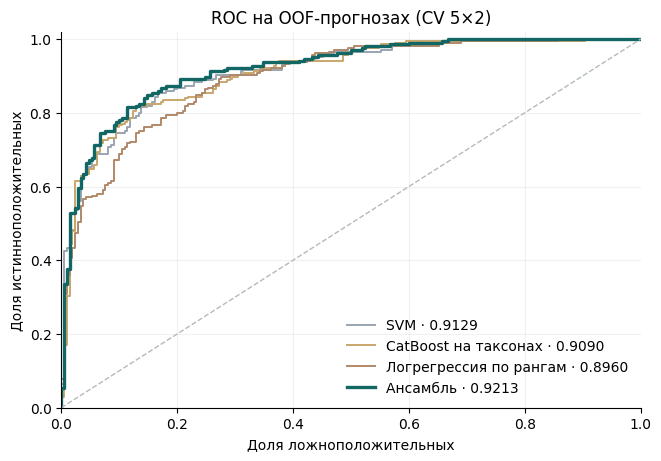

In [16]:
if RUN_VALIDATION:
    with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False,
                         "axes.spines.right": False}):
        fig, ax = plt.subplots(figsize=(6.5, 4.5), layout="constrained")
        for name, color, width in [("SVM", "#9AA5B1", 1.4), ("CatBoost на таксонах", "#C9A66B", 1.4), ("Логрегрессия по рангам", "#B08968", 1.4), (FINAL, "#126764", 2.4)]:
            x, y, _ = roc_curve(dataset.y, oof[name])
            auc = roc_auc_score(dataset.y, oof[name])
            ax.plot(x, y, lw=width, color=color, label=f"{name} · {auc:.4f}")
        ax.plot([0, 1], [0, 1], "--", color="#B3BABF", lw=1)
        ax.set(xlim=(0, 1), ylim=(0, 1.02), title="ROC на OOF-прогнозах (CV 5×2)",
               xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
        ax.grid(alpha=0.17)
        ax.legend(loc="lower right", frameon=False)
        plt.show()

**Как читать итог.** Главная цифра это OOF ROC AUC ансамбля на схеме CV 5 × 2. Сравнение с AUC при LOCO показывает, насколько обычная валидация оптимистична. Если AUC на какой-то когорте заметно ниже остальных, модель хуже переносится на эту когорту. Подбор конфигурации велся на тех же 415 образцах, поэтому реальное качество на закрытой валидации может быть ниже.

### Порог классификации и confusion matrix

ROC AUC не зависит от порога. Чтобы получить метки, образец с вероятностью не ниже порога считается case: чем ниже порог, тем меньше пропущенных больных (выше Sensitivity), но больше ложных тревог (ниже Specificity).

Ниже для **каждой из трёх схем валидации** (CV 5×2, CV по классу и когорте, LOCO) строятся таблица метрик для порогов 0.1–0.9 и confusion matrix для порогов `THRESHOLDS_CM`. Работа идёт на OOF-вероятностях ансамбля, то есть на прогнозах моделей, не видевших образец. Цвет клетки показывает долю от истинного класса, число показывает количество образцов. В LOCO прогнозы каждой когорты получены своей моделью, поэтому это сводная картина по пяти моделям. Порог Юдена подобран на тех же OOF, его оценка слегка оптимистична.

In [ ]:
from sklearn.metrics import confusion_matrix
from scipy.special import logit

THRESHOLDS_TABLE = np.round(np.arange(0.10, 0.91, 0.10), 2)   # сетка порогов для таблиц
THRESHOLDS_CM = [0.3, 0.4, 0.5, 0.6, 0.7]                     # пороги для графика confusion matrix


def threshold_metrics(y_true, proba, threshold):
    """Confusion matrix и метрики при заданном пороге (case, если proba >= threshold)."""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if tp + fn else np.nan          # доля найденных case
    specificity = tn / (tn + fp) if tn + fp else np.nan          # доля верно опознанных control
    precision = tp / (tp + fp) if tp + fp else np.nan            # доля настоящих case среди тревог
    f1 = 2 * precision * sensitivity / (precision + sensitivity) if precision + sensitivity else np.nan
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "Accuracy": (tp + tn) / len(y_true),
            "Sensitivity": sensitivity, "Specificity": specificity, "Precision": precision,
            "F1": f1, "Balanced acc.": (sensitivity + specificity) / 2}


def to_probability(scores):
    """Калиброванная вероятность ансамбля (если калибратор есть), иначе исходная сигмоида."""
    if calibrator is None:
        return scores
    return calibrator.predict_proba(logit(np.clip(scores, 1e-7, 1 - 1e-7))[:, None])[:, 1]


if RUN_VALIDATION:
    y_true = dataset.y
    # OOF-вероятности ансамбля для каждой из трёх схем валидации
    scheme_proba = {"CV 5×2": to_probability(oof[FINAL]),
                    "CV класс+когорта": to_probability(oof_cohort[FINAL]),
                    "LOCO": to_probability(oof_loco[FINAL])}

    for scheme, proba in scheme_proba.items():
        fpr, tpr, roc_thresholds = roc_curve(y_true, proba)
        youden = roc_thresholds[np.argmax(tpr - fpr)]
        rows = {f"{t:.2f}": threshold_metrics(y_true, proba, t) for t in THRESHOLDS_TABLE}
        rows[f"{youden:.3f} · макс. Юден"] = threshold_metrics(y_true, proba, youden)
        table = pd.DataFrame(rows).T.rename_axis("Порог")
        table[["TN", "FP", "FN", "TP"]] = table[["TN", "FP", "FN", "TP"]].astype(int)
        print(f"\n=== {scheme} · ROC AUC {roc_auc_score(y_true, proba):.4f} ===")
        display(table.round(3))


In [ ]:
from matplotlib.colors import LinearSegmentedColormap

if RUN_VALIDATION:
    cmap = LinearSegmentedColormap.from_list("teal", ["#FFFFFF", "#126764"])
    class_names = ["Control", "Case"]
    n_rows, n_cols = len(scheme_proba), len(THRESHOLDS_CM)
    with plt.rc_context({"font.family": "DejaVu Sans"}):
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.3 * n_cols, 3.4 * n_rows),
                                 layout="constrained", squeeze=False)
        for row, (scheme, proba) in enumerate(scheme_proba.items()):
            for col, threshold in enumerate(THRESHOLDS_CM):
                ax = axes[row, col]
                matrix = confusion_matrix(y_true, (proba >= threshold).astype(int), labels=[0, 1])
                share = matrix / matrix.sum(axis=1, keepdims=True)      # доля от истинного класса
                ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
                for i in range(2):
                    for j in range(2):
                        ax.text(j, i, f"{matrix[i, j]}\n({share[i, j]:.0%})", ha="center", va="center",
                                fontsize=11, color="white" if share[i, j] > 0.55 else "#222222")
                ax.set(title=f"порог {threshold:.2f} · Sens {share[1, 1]:.2f} · Spec {share[0, 0]:.2f}",
                       xticks=[0, 1], yticks=[0, 1], xticklabels=class_names, yticklabels=class_names)
                ax.title.set_fontsize(9)
                if col == 0:
                    ax.set_ylabel(f"{scheme}\nИстина", fontsize=10)
                if row == n_rows - 1:
                    ax.set_xlabel("Предсказание", fontsize=10)
        fig.suptitle("Confusion matrix ансамбля при разных порогах: все три схемы валидации (OOF)", fontsize=13)
        plt.show()


## 6. Ключевые таксоны

**Зачем этот блок.** Он отвечает на вопрос «какие бактерии несут сигнал». Для 15 таксонов с наибольшим по модулю эффектом показаны:

- эффект (AUC − 0.5): положительный означает обогащение у больных, отрицательный означает обеднение;
- AUC в каждой когорте и число когорт с тем же знаком эффекта, то есть устойчивость сигнала;
- доля образцов, где таксон обнаружен, среди case и среди control.

Таблица описательная: она считается по всему train и в обучении не участвует. Ассоциация не доказывает причинности.

In [17]:
def top_taxa_table(ds, n_top=15):
    raw = ds.raw[: len(ds.y)]
    y, cohorts = ds.y, ds.cohort[: len(ds.y)]
    effects = cohort_effects(raw, y, cohorts)
    rows = []
    for j in np.argsort(-np.abs(effects))[:n_top]:
        per_cohort = {c: roc_auc_score(y[cohorts == c], raw[cohorts == c, j]) for c in sorted(set(cohorts))}
        same_sign = sum(np.sign(v - 0.5) == np.sign(effects[j]) for v in per_cohort.values())
        rows.append({"Таксон": ds.taxa[j].split(" [")[0], "Эффект (AUC−0.5)": effects[j],
                     **{f"AUC {c}": v for c, v in per_cohort.items()},
                     "Когорт с тем же знаком": f"{same_sign}/{len(per_cohort)}",
                     "У case": (raw[y == 1, j] > 0).mean(), "У control": (raw[y == 0, j] > 0).mean()})
    return pd.DataFrame(rows).set_index("Таксон")


display(top_taxa_table(dataset).round(3))

,Эффект (AUC−0.5),AUC AUS,AUC CHI,AUC FRA,AUC GER,AUC USA,Когорт с тем же знаком,У case,У control
Таксон,,,,,,,,,
Parvimonas micra,0.235,0.775,0.809,0.688,0.754,0.620,5/5,0.600,0.205
Gemella morbillorum,0.197,0.794,0.777,0.634,0.651,0.609,5/5,0.556,0.210
Fusobacterium nucleatum s. animalis,0.167,0.718,0.659,0.684,0.654,0.619,5/5,0.390,0.076
Solobacterium moorei,0.161,0.616,0.749,0.605,0.722,0.576,5/5,0.439,0.133
Peptostreptococcus stomatis,0.159,0.623,0.712,0.635,0.698,0.602,5/5,0.439,0.152
Hungatella hathewayi,0.158,0.583,0.713,0.710,0.646,0.623,5/5,0.673,0.414
Ruminococcus torques,0.158,0.705,0.688,0.591,0.676,0.617,5/5,0.937,0.838
unknown Clostridiales,0.156,0.621,0.741,0.580,0.684,0.629,5/5,0.590,0.300
unknown Dialister,0.154,0.629,0.666,0.689,0.663,0.613,5/5,0.337,0.024


## 7. Финальное обучение и `submission.csv`

**Зачем этот блок.** Он выпускает итоговый файл. Ансамбль обучается на **всех 415 размеченных образцах** `train.csv` и оценивает 160 образцов `test.csv`. Колонка `label` содержит вероятность класса 1 (после калибровки из раздела 5; без валидации берётся сигмоида от оценки). Порядок строк совпадает с `test.csv`. Проверки в конце гарантируют, что длина, порядок `sample_id` и диапазон вероятностей корректны.

In [18]:
all_training_rows = np.arange(len(train))
all_test_rows = np.arange(len(train), len(train) + len(test))
with threadpool_limits(limits=1, user_api="blas"):
    test_margin = fit_predict(dataset, all_training_rows, all_test_rows)[FINAL]
probability = (calibrator.predict_proba(test_margin[:, None])[:, 1]
               if calibrator is not None else expit(test_margin))
submission = pd.DataFrame({"sample_id": test.sample_id, "label": probability})
assert len(submission) == len(test)
assert submission.sample_id.equals(test.sample_id)
assert submission.label.between(0, 1).all()
assert submission.label.nunique() > 1
submission.to_csv(OUTPUT_PATH, index=False, float_format="%.12f")
print(f"{OUTPUT_PATH.name} · {len(submission)} прогнозов")

submission.csv · 160 прогнозов


## Справочник

### Термины

| Термин | Что означает |
|---|---|
| **mOTU** | Единица таксономического профилирования метагеномов; в данных 849 колонок с относительными численностями |
| **Относительная численность** | Доля таксона в образце; сумма по образцу не превышает 1 |
| **CLR** | Центрированное логарифмическое отношение: `log(доля)` минус среднее таких логарифмов по образцу. Подходит для композиционных данных, где важны не абсолютные значения, а соотношения |
| **Эмпирический ранг** | Положение значения среди значений обучающей части, число от 0 до 1; снижает влияние выбросов |
| **Ковариата** | Показатель образца, не относящийся к микробиоте (возраст, ИМТ, пол, когорта, глубина секвенирования), который может быть связан с меткой |
| **Когорта** | Источник данных (страна или исследование); AUS, CHI, FRA, GER, USA |
| **Эффект таксона** | AUC − 0.5, посчитанный внутри когорты и усреднённый по когортам |
| **Ядро SVM** | Функция, которая измеряет сходство двух образцов. RBF сходство падает с расстоянием, ядро Лапласа использует манхэттенское расстояние |
| **CatBoost** | Градиентный бустинг на деревьях решений |
| **Ансамбль** | Смесь оценок нескольких моделей; здесь 52.5% SVM, 22.5% CatBoost и 25% логистической регрессии |
| **ROC AUC** | Вероятность того, что случайный case получит оценку выше случайного control; 0.5 соответствует угадыванию, 1.0 идеальному разделению |
| **OOF** | Out-of-fold: прогноз для образца, полученный моделью, не видевшей его при обучении |
| **LOCO** | Leave-One-Cohort-Out: когорта целиком исключается из обучения и становится validation |
| **Калибровка** | Монотонное преобразование оценок в вероятности; порядок образцов и AUC не меняются |

### Венгерский алгоритм (кратко)

Венгерский алгоритм решает **задачу о назначениях**: как распределить N объектов по N местам так, чтобы суммарная стоимость была минимальной. В коде это функция `scipy.optimize.linear_sum_assignment`.

В нашем решении «объекты» это таксоны, «места» это слоты кластеров, а «стоимость» это расстояние `1 − |корреляция рангов CLR|` между таксоном и центром кластера. Каждому кластеру выделяется одинаковое число слотов (`ceil(число таксонов / 40)`), поэтому алгоритм формирует **сбалансированные** кластеры. Обычная кластеризация k-средних или k-медоидов может дать кластер из одного таксона и кластер из сотен. Подробный разбор с числовым примером приведён в отдельной пояснительной записке.